In [1]:
# Libraries:
import numpy as np
import matplotlib.pyplot as plt
import dill
import sys
import os

import pysindy as ps
import D_CODE # we import D_CODE also inside toolbox.

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..'))) # include parent directory in the path
from data import SINDy_data
from data import data
from data import equations

from toolbox.auxiliary_functions import set_param_freq
from toolbox.symbolic_SINDy import symbolic_SINDy

# Seed:
np.random.seed(999)

/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


#### Case $n$, $k$, $k_a$ and $k_y$ fixed
Consider the modified Van der Pol system with a nonlinear forcing term
$$
\begin{cases}
\dot{x} = \frac{k y^n}{k_a + y^n} \\
\dot{y} = - k_y y
\end{cases}
$$
and with $n=2.8$, $k=1$, $k_a=4$ and $k_y=0.1$ fixed.

In [2]:
# Select ODE & settings:
ode_name = 'HillODE' # help="name of the ode", type=str
ode_param = '2.8,1,4,0.1' # help="parameters of the ode (default: None)", type=str, default=None
freq = 10 # help="sampling frequency", type=float, default=10
freq_SR = 10
n_sample = 50 # help="number of trajectories", type=int, default=100
noise_ratio = 0.01 # help="noise level (default 0)", type=float, default=0.
seed = 102 # help="random seed", type=int, default=0
n_seed = 1 # help="random seed", type=int, default=10

ode_param, freq = set_param_freq(ode_param, freq)

ode = equations.get_ode(ode_name, ode_param)
dt = 1 / freq
dim_x = 2
dim_k = 0
time_vector = np.arange(0, ode.T + dt, dt)
T = ode.T

In [3]:
# # Generate data:
# X_list, dX_list, param_list, feature_names = SINDy_data.SINDy_data(ode_name, ode_param, freq, n_sample, noise_ratio, dim_x, dim_k)
# print(np.shape(X_list), np.shape(dX_list), np.shape(param_list))
# print(feature_names)

# # Save data:
# file_path = 'saved/data/hillODE_data.pkl'
# os.makedirs(os.path.dirname(file_path), exist_ok=True)
# with open(file_path, 'wb') as f:
#     dill.dump((X_list, dX_list, param_list, feature_names), f)

In [4]:
# Uploda data:
file_path = 'saved/data/hillODE_data.pkl'
with open(file_path, 'rb') as f:
    X_list, dX_list, param_list, feature_names = dill.load(f)

print(np.shape(X_list), np.shape(dX_list), np.shape(param_list))
print(feature_names)

(50, 150, 2) (50, 150, 2) (0,)
['X0', 'X1']


> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Hill ODE.
>
> Inside the `gplearn` library, in `genetic.py`, set the filter:
>
>   ```python
>   min_length = 5
>   max_length = 10 
>   ```

In [5]:
# Symbolic-SINDy call and fit
model = symbolic_SINDy(SR_method='D-CODE', 
                       x_id=0,
                       degree=3,
                       threshold=0.05,
                       product=False)

model.fit(X_list=X_list, dX_list=dX_list, param_list=param_list,
          feature_names=feature_names, dt=dt, ode=ode, ode_name=ode_name,
          ode_param=ode_param, freq_SR=freq_SR, n_sample=n_sample, 
          noise_ratio=noise_ratio, seed=seed, n_seed=n_seed, 
          T0=0, T=T, dim_x=dim_x, dim_k=dim_k)

Fitting Smart-SINDy model

Searching for additonal building blocks -> D-CODE call:

Running with: ode_name=HillODE, ode_param=[2.8, 1.0, 4.0, 0.1], x_id=0, freq=10, n_sample=50, noise_sigma=0.01, seed=102, n_seed=1
Dataset shape:  (301, 50, 2)
Functions set:  {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    11.81      6.18395e+37       21          9.07699           8.3469      3.74m
   1     9.55      1.22138e+18        7          3.12836          2.97984      3.89m
   2     6.74      7.49518e+17        7          2.85531          5.43732      2.80m
 
promising programs:
div(div(div(mul(X1, X1), div(X0, X0)), add(div(2.037, X1), X1)), X1)
div(neg(neg(X1)), add(div(2.751, X1), X1))
div(add(pow(X1, 1.037), div(div(X1, X1), add(X0, X0))

##### Plot per report

In [6]:
from report import evaluate_traj
final_model = model.model # To get from Symbolic-SINDy class the fitted model as SINDy built-in type

In [7]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(final_model, ode, freq, n_test, [10., 10.], [0., 0.], dim_k)
print('Best SINDy Model RMSE: ', rmse)

Best SINDy Model RMSE:  0.00470103524283796


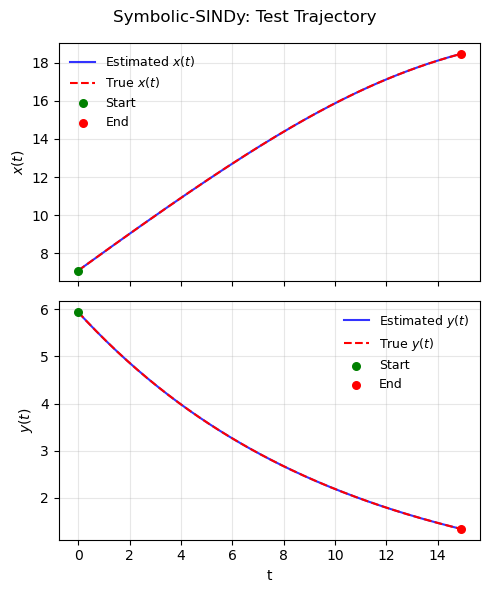

In [8]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [7., 6.]
title = 'Symbolic-SINDy: Test Trajectory'
evaluate_traj(final_model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

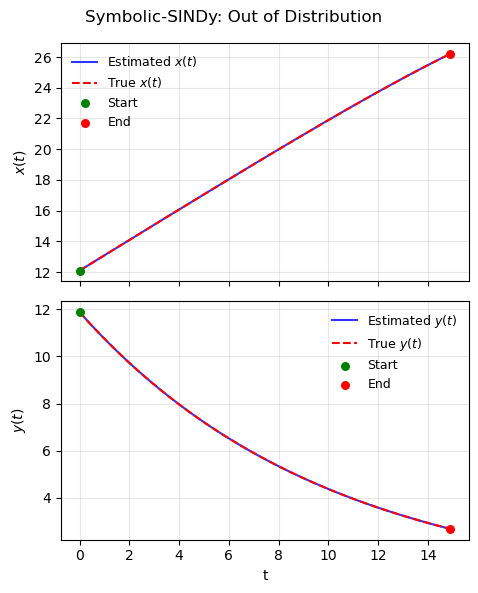

In [9]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [12, 12]
title = 'Symbolic-SINDy: Out of Distribution'
evaluate_traj(final_model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

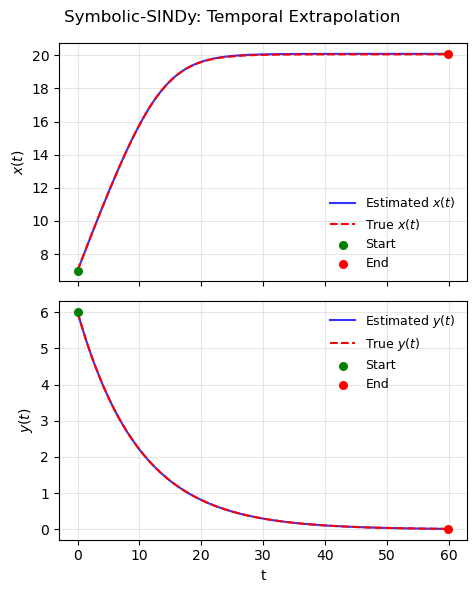

In [10]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [7, 6]
title = 'Symbolic-SINDy: Temporal Extrapolation'
evaluate_traj(final_model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=60)

##### Uncertainty Quantification

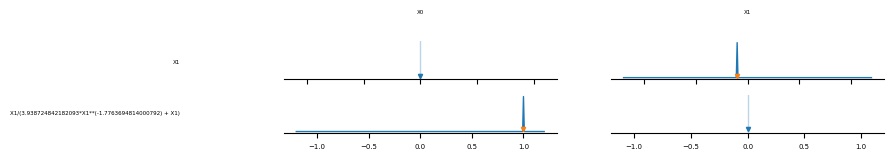

In [11]:
model.ensemble(X_list=X_list, dX_list=dX_list, param_list=param_list,
               feature_names=feature_names, dt=dt, n_models=200)
model.uq_plot(feature_names=feature_names)